# [기초-실습] 통계 101x데이터 분석: (5-6장) 다양한 가설검정

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [3]:
# # 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# # 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
# !pip install statsmodels
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv
# !rm ~/.cache/matplotlib -rf

In [4]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 게임 아이템 뽑기 확률, 정말 10%일까? (난이도: 하)

**📘 문제**

- 어떤 게임 개발사에서 새로운 아이템의 뽑기 확률이 **10%**로 설정되었다고 주장하고 있습니다.

- 그런데 유저 커뮤니티에서는 "실제 확률은 10%보다 낮은 것 같다"는 의혹이 제기되었습니다.

- 이를 확인하기 위해 한 유저가 아이템을 **200번 뽑았고, 그중 12번 성공**했습니다.

- 이번 실습에서는 **이항검정(Binomial Test)**으로 이 결과가 개발사의 주장을 기각할 만큼 유의미한지 확인하고,
  시뮬레이션을 통해 **p-값이 무엇을 의미하는지**를 직접 눈으로 확인해 봅니다.

In [5]:
# 문제 설정
n = 200  # 총 시행 횟수
x = 12   # 관찰된 성공 횟수
p = 0.1  # 귀무가설에서의 성공 확률

print(f"관찰 결과: {n}번 시도 중 {x}번 성공 (관찰 성공률 {x/n:.1%})")

관찰 결과: 200번 시도 중 12번 성공 (관찰 성공률 6.0%)


**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 이항검정을 수행하여 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"만약 개발사의 주장대로 실제 확률이 정말 10%라면"** 200번 뽑기에서 성공 횟수가 어떻게 분포하는지 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 우리가 관찰한 '12번 성공'이 얼마나 희귀한 일인지 관찰해 봅시다.

#### [문제 1] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
- 귀무가설(H₀): 아이템 뽑기의 실제 성공 확률은 10%이다. (p = 0.1)
    - → 개발사의 주장이 맞다.
- 대립가설(H₁): 아이템 뽑기의 실제 성공 확률은 10%보다 낮다. (p < 0.1)
    - → 유저 커뮤니티의 의혹이 맞다.

In [43]:
from scipy.stats import binom
print(binom.cdf(12, 200, 0.1)*100)   # 0.0320 → 3.2%

3.20465287969066


In [49]:
# [문제 1] Q2. 이항검정을 수행하고 p-값을 계산해봅시다.
# '확률이 더 낮은 것 같다'는 주장을 검증하려면 alternative 인수를 어떻게 설정해야 할까요?

from scipy.stats import binomtest

n = 200        # 시행 횟수
k = 12         # 성공 횟수
p0 = 0.1       # 귀무가설의 확률 (개발사 주장)

# 대립가설이 "10%보다 낮다"이므로 alternative='less'
result = binomtest(k=k, n=n, p=p0, alternative='less')
p_value = result.pvalue

print(f"p-값: {p_value:.4f}")

p-값: 0.0320


| 코드 | 읽는 법 |
|---|---|
| `alternative='less'` | 대립가설: 10%보다 **작다** |
| `alternative='greater'` | 대립가설: 10%보다 **크다** |
| `alternative='two-sided'` | 대립가설: 10%와 **다르다** (양쪽) |

findfont: Failed to find font weight bold for AppleGothic, now using 400.
findfont: Failed to find font weight bold for AppleGothic, now using 400.


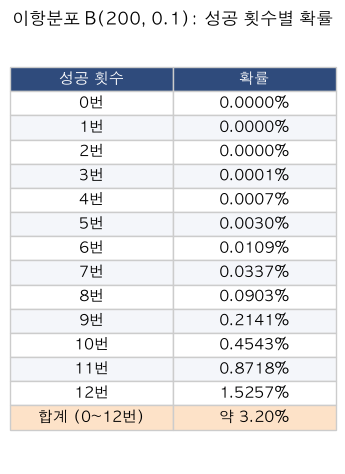

In [48]:
import matplotlib.pyplot as plt
from scipy.stats import binom

# 한글 폰트 설정 (Mac: AppleGothic / Windows: Malgun Gothic)
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

n, p = 200, 0.1

# 0~12번 각각의 확률 + 합계
rows = [[f"{k}번", f"{binom.pmf(k, n, p) * 100:.4f}%"] for k in range(13)]
rows.append(["합계 (0~12번)", f"약 {binom.cdf(12, n, p) * 100:.2f}%"])

fig, ax = plt.subplots(figsize=(4.2, 5.6))
ax.axis('off')

table = ax.table(cellText=rows, colLabels=["성공 횟수", "확률"],
                 loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.45)

# 색상 꾸미기
for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor('#cccccc')
    if r == 0:                      # 헤더
        cell.set_facecolor('#2f4b7c')
        cell.set_text_props(color='white', weight='bold')
    elif r == len(rows):            # 합계 행
        cell.set_facecolor('#fde2c8')
        cell.set_text_props(weight='bold')
    elif r % 2 == 0:                # 줄무늬
        cell.set_facecolor('#f4f6fa')

ax.set_title("이항분포 B(200, 0.1): 성공 횟수별 확률", fontsize=12, weight='bold')
plt.show()

In [46]:
# [문제 1] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

from scipy.stats import binomtest

alpha = 0.05

# 이항검정: 200번 중 12번 성공, 귀무가설 확률 10%, 단측(왼쪽) 검정
result = binomtest(k=12, n=200, p=0.1, alternative='less')
p_value = result.pvalue

print(f"p-값: {p_value:.4f}")

if p_value < alpha:
    print("p-값이 유의수준보다 작으므로 귀무가설을 기각합니다.")
    print("→ 실제 확률은 10%보다 낮다고 볼 수 있습니다.")
else:
    print("p-값이 유의수준보다 크므로 귀무가설을 기각할 수 없습니다.")
    print("→ 실제 확률이 10%보다 낮다고 보기 어렵습니다.")

p-값: 0.0320
p-값이 유의수준보다 작으므로 귀무가설을 기각합니다.
→ 실제 확률은 10%보다 낮다고 볼 수 있습니다.


In [50]:
# [문제 1] Q4. H₀가 사실(실제 확률 = 10%)이라고 가정하고,
# 200번 뽑기를 10,000번 반복하는 시뮬레이션을 수행해봅시다.
# 힌트: numpy의 이항분포 랜덤 함수(np.random.binomial)를 사용해보세요.

import numpy as np

np.random.seed(42)   # 실행할 때마다 같은 결과가 나오도록 고정

n = 200              # 한 번의 실험에서 뽑는 횟수
p0 = 0.1             # 귀무가설의 확률 (10%)
n_sim = 10000        # 실험 반복 횟수

# 200번 뽑기를 10,000번 반복 → 각 실험의 성공 횟수 10,000개
simulated = np.random.binomial(n=n, p=p0, size=n_sim)

print("앞 10개 결과:", simulated[:10])
print("평균 성공 횟수:", simulated.mean())

앞 10개 결과: [19 27 23 21 16 16 14 25 21 22]
평균 성공 횟수: 19.9144


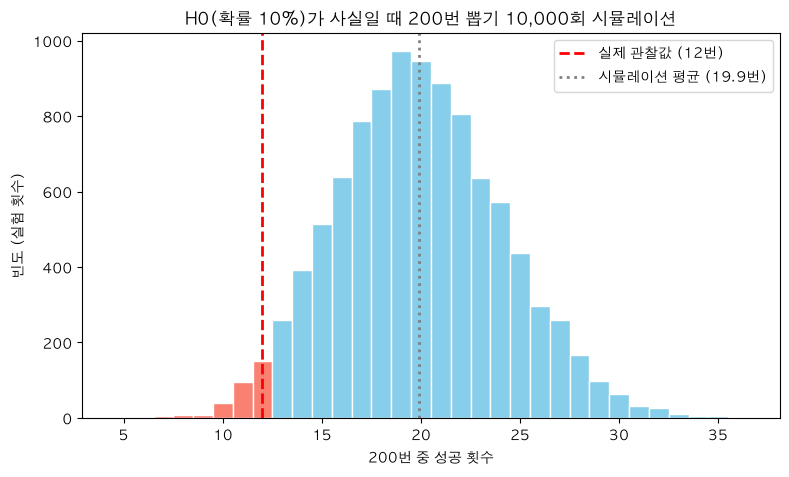

In [51]:
# [문제 1] Q5. 시뮬레이션 결과를 히스토그램으로 그려봅시다.
# 실제 관찰값(12번 성공)을 세로선으로 함께 표시해 봅시다.

import matplotlib.pyplot as plt

# 한글 폰트 설정 (Mac)
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

observed = 12   # 실제 관찰값

# 막대를 정수(성공 횟수) 하나당 하나씩 그리기 위한 구간 설정
bins = np.arange(simulated.min(), simulated.max() + 2) - 0.5

plt.figure(figsize=(9, 5))
counts, edges, patches = plt.hist(simulated, bins=bins,
                                  color='skyblue', edgecolor='white')

# 12번 이하 막대는 빨간색으로 강조 (p-값에 해당하는 영역)
for patch, left in zip(patches, edges[:-1]):
    if left + 0.5 <= observed:
        patch.set_facecolor('salmon')

# 실제 관찰값 세로선
plt.axvline(observed, color='red', linestyle='--', linewidth=2,
            label=f'실제 관찰값 ({observed}번)')
# 시뮬레이션 평균 세로선
plt.axvline(simulated.mean(), color='gray', linestyle=':', linewidth=2,
            label=f'시뮬레이션 평균 ({simulated.mean():.1f}번)')

plt.title('H0(확률 10%)가 사실일 때 200번 뽑기 10,000회 시뮬레이션')
plt.xlabel('200번 중 성공 횟수')
plt.ylabel('빈도 (실험 횟수)')
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- Q2에서 구한 p-값은 시뮬레이션 그래프의 어느 부분에 해당하며, 무엇을 의미하나요?

- 시뮬레이션 그래프를 볼 때, 우리가 관찰한 '12회 성공'은 개발사의 주장이 맞다는 가정 하에 흔한 일인가요, 드문 일인가요?

- 이 시뮬레이션 경험을 통해 "p-값이 작으면 귀무가설을 기각한다"는 규칙을 친구에게 어떻게 더 쉽게 설명할 수 있을까요?

- 만약 200번이 아니라 1,000번을 뽑아 같은 성공률(6%)이 나왔다면, p-값은 어떻게 달라질까요?

**🧠 데이터를 어떻게 읽을까요?**

- **Q2에서 구한 p-값은 시뮬레이션 그래프의 어느 부분에 해당하며, 무엇을 의미하나요?**
    - p-값(약 0.032)은 히스토그램에서 **빨간 세로선(12회) 왼쪽, 즉 12회 이하 막대들의 넓이**에 해당한다.
    - 개발사 주장(10%)이 사실이라고 가정했을 때, 200번 뽑아서 **12회 이하로 성공할 확률이 약 3.2%** 라는 뜻이다.
    - 실제로 시뮬레이션 10,000번 중 12회 이하가 나온 비율도 약 3.1%로, 이항검정 결과와 거의 같다.

- **우리가 관찰한 '12회 성공'은 개발사의 주장이 맞다는 가정 하에 흔한 일인가요, 드문 일인가요?**
    - **드문 일**이다.
    - 확률이 10%라면 대부분의 결과는 평균 20회 근처에 몰려 있고, 12회는 분포의 왼쪽 끝자락에 위치한다.
    - 100명 중 약 3명 정도만 겪는 결과로, 유의수준 5%보다 드물기 때문에 우연으로 보기 어렵다.

- **"p-값이 작으면 귀무가설을 기각한다"는 규칙을 친구에게 어떻게 쉽게 설명할 수 있을까요?**
    - "개발사 말대로 10%가 맞다고 치고 1만 명한테 200번씩 뽑게 해봤더니, 12번 이하로 나온 사람은 겨우 3% 정도였어."
    - "그렇게 드문 일이 하필 나한테 일어났다고 보는 것보다, **애초에 10%라는 말이 틀렸다**고 보는 게 더 자연스럽지."
    - 즉 p-값은 **'가정이 맞다면 이 결과가 나올 확률'**이고, 이게 너무 작으면 가정 자체를 의심하는 것이다.

- **만약 1,000번을 뽑아 같은 성공률(6%, 60회)이 나왔다면, p-값은 어떻게 달라질까요?**
    - p-값은 **훨씬 작아진다.** (약 0.0000044, 즉 0.00044%)
    - 뽑는 횟수가 많아질수록 결과가 평균(10%) 근처에 더 촘촘하게 모이기 때문에, 6%처럼 벗어난 결과는 우연으로 나오기가 훨씬 어려워진다.
    - 같은 6%라도 **표본이 클수록 증거가 강해져서** 귀무가설을 더 확실하게 기각할 수 있다.

# 문제 2. 과자 한 봉지의 중량은 150g이 맞을까? (난이도: 하)

**📘 문제**

- 한 식품 공장에서 생산하는 과자 한 봉지의 **목표 중량은 150g**입니다.

- 품질관리팀은 생산 공정이 목표 중량을 잘 맞추고 있는지 확인하기 위해,
  생산된 과자 **30봉지를 무작위로 추출**하여 무게를 측정했습니다.

- 이번 실습에서는 **일표본 t-검정(One-sample t-Test)**으로 표본 평균이 목표 중량과 유의미하게 다른지 검증하고,
  **"평균이 정확히 150g이라면"** 어떤 표본 평균들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

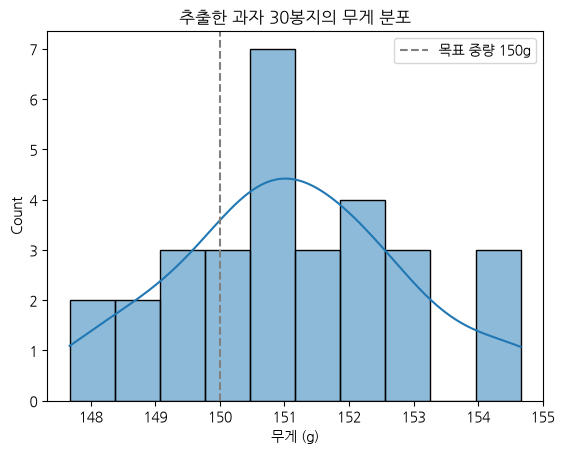

In [12]:
# 데이터 생성 (과자 30봉지의 무게 측정값)
np.random.seed(42)
sample_weights = np.random.normal(loc=151.5, scale=2, size=30)
pop_mean = 150  # 목표 중량 (모평균)

# 표본 분포 시각화
sns.histplot(sample_weights, bins=10, kde=True)
plt.axvline(x=pop_mean, color='gray', linestyle='--', label='목표 중량 150g')
plt.title("추출한 과자 30봉지의 무게 분포")
plt.xlabel("무게 (g)")
plt.legend()
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 일표본 t-검정을 수행하여 t-통계량과 p-값을 구하고, 유의수준 0.05를 기준으로 결론을 내려봅시다.

- **"평균 무게가 정확히 150g이라면"** 30개짜리 표본의 평균이 어떻게 분포하는지 10,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 표본 평균이 그 분포에서 어디에 위치하는지 관찰해 봅시다.

In [13]:
# [문제 2] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설):
# H₁ (대립가설):

In [14]:
# [문제 2] Q2. 일표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.

# 여기에 코드를 작성해주세요.

In [15]:
# [문제 2] Q3. 유의수준 0.05를 기준으로 통계적 결론을 내리는 코드를 작성해봅시다.
# alpha = 0.05

# 여기에 코드를 작성해주세요.

In [16]:
# [문제 2] Q4. H₀가 사실(평균 = 150g)이라고 가정하고, 30개짜리 표본을 10,000번 뽑아
# 각 표본의 평균을 리스트에 저장해봅시다.
# 힌트: 표준편차는 우리가 가진 표본의 표준편차를 사용한다고 가정하고, for 반복문을 사용해보세요.

# 여기에 코드를 작성해주세요.

In [17]:
# [문제 2] Q5. 시뮬레이션으로 얻은 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 표본 평균을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

- Q5의 히스토그램은 무엇을 나타내나요? 이 분포의 모양이 정규분포와 비슷한 이유는 무엇일까요? (힌트: 4장에서 배운 중심극한정리)

- 우리가 실제로 관찰한 표본 평균(세로선)은 이 분포에서 흔하게 나타나는 값인가요? Q2의 p-값과 이 시각적 위치는 어떻게 관련되나요?

- 만약 p-값이 0.001이었다면, 세로선은 그래프의 어디쯤에 위치할 것으로 예상되나요?

- 이 결과는 공장 입장에서 어떤 조치를 취해야 함을 시사할까요? (목표보다 무겁게 나오는 것은 어떤 손실일까요?)

In [18]:
# [문제 2] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 3. 어떤 온라인 학습 방식이 더 효과적일까? (난이도: 중)

**📘 문제**

- 한 교육 기업에서 두 가지 다른 온라인 학습 방식(A, B)을 개발했습니다.

- 방식 A가 방식 B보다 학생들의 성적 향상에 더 효과적인지 알아보기 위해,
  두 그룹의 학생들에게 각각 다른 방식으로 한 달간 학습시킨 후 시험을 보게 했습니다.

- 이번 실습에서는 **이표본 t-검정(Two-sample t-Test)**으로 두 방식의 평균 점수 차이를 검증합니다.
  단, t-검정의 기본 가정인 **정규성**과 **등분산성**을 먼저 확인해야 합니다.

- 또한 **"두 방식의 효과가 완전히 똑같다면"** 우연히 나타날 수 있는 점수 차이의 범위를 시뮬레이션으로 확인해 봅니다.

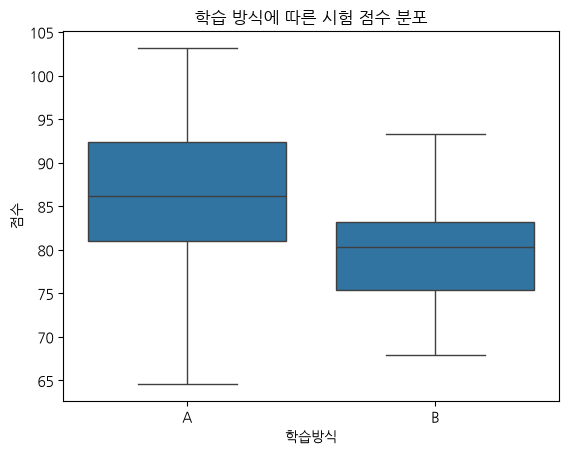

In [19]:
# 데이터 생성 (두 학습 방식의 시험 점수)
np.random.seed(0)
group_a_scores = np.random.normal(loc=85, scale=8, size=50)
group_b_scores = np.random.normal(loc=80, scale=7, size=50)

df_scores = pd.DataFrame({'점수': np.concatenate([group_a_scores, group_b_scores]),
                          '학습방식': ['A']*50 + ['B']*50})

# 두 그룹의 점수 분포 시각화
sns.boxplot(x='학습방식', y='점수', data=df_scores)
plt.title("학습 방식에 따른 시험 점수 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 두 그룹에 대해 **정규성 검정(Shapiro-Wilk test)**을 수행해 봅시다. (H₀: 데이터는 정규분포를 따른다.)

- **등분산성 검정(Levene's test)**을 수행해 봅시다. (H₀: 두 그룹의 분산은 같다.)

- 가정 검토 결과에 따라 `equal_var` 인수를 설정하여 **이표본 t-검정**을 수행해 봅시다.

- 두 그룹 데이터를 모두 합친 뒤 무작위로 다시 나누는 방식으로, **"두 방식의 효과가 같을 때"**의 평균 차이 분포를 시뮬레이션해 봅시다.

In [20]:
# [문제 3] Q1. 두 그룹에 대해 각각 정규성 검정(Shapiro-Wilk test)을 수행하고 p-값을 출력해봅시다.
# H₀: 데이터는 정규분포를 따른다.

# 여기에 코드를 작성해주세요.

In [21]:
# [문제 3] Q2. 두 그룹에 대해 등분산성 검정(Levene's test)을 수행하고 p-값을 출력해봅시다.
# H₀: 두 그룹의 분산은 같다.

# 여기에 코드를 작성해주세요.

In [22]:
# [문제 3] Q3. 이표본 t-검정을 수행하여 t-통계량과 p-값을 구해봅시다.
# H₀: 두 그룹의 평균은 같다. / H₁: 두 그룹의 평균은 다르다.
# 등분산성 가정을 만족했는지 여부에 따라 equal_var 인수를 설정해보세요.

# 여기에 코드를 작성해주세요.

In [23]:
# [문제 3] Q4. H₀가 사실(두 그룹의 평균이 같다)이라고 가정하고 시뮬레이션을 10,000번 수행해봅시다.
# 두 그룹의 데이터를 모두 합친 뒤(np.concatenate), 매 반복마다 비복원추출로 50개(가상 A그룹)와
# 나머지 50개(가상 B그룹)로 나누어 두 그룹의 평균 차이를 계산하고 리스트에 저장해보세요.
# 힌트: np.random.permutation 을 사용해보세요.

# 여기에 코드를 작성해주세요.

In [24]:
# [문제 3] Q5. 시뮬레이션으로 얻은 평균 차이의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 평균 차이(A그룹 평균 - B그룹 평균)를 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

- 정규성 검정과 등분산성 검정의 p-값은 각각 어떻게 해석해야 하나요? 이 결과는 이표본 t-검정을 사용하는 데 문제가 없음을 보여주나요?

- Q5의 히스토그램 중심이 0에 가까운 이유는 무엇일까요?

- 실제 관찰된 평균 차이(세로선)는 "두 방식의 효과가 같다"고 가정했을 때 우연히 나타날 수 있는 범위 안에 있나요, 벗어나나요?

- 이 시각적 판단과 Q3의 p-값은 어떤 관계가 있나요?

- 통계적으로 유의미한 차이가 있다면, 교육 기업은 이 결과를 어떻게 활용할 수 있을까요?

In [25]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 4. 연령대별로 선호하는 영화 장르가 다를까? (난이도: 중)

**📘 문제**

- 한 영화관에서 고객의 **연령대(20대, 30대, 40대)**에 따라 선호하는 **영화 장르(액션, 로맨스)**에 차이가 있는지 궁금해졌습니다.

- 이를 알아보기 위해 300명의 고객을 대상으로 설문조사를 진행하여 분할표를 얻었습니다.

- 이번 실습에서는 **카이제곱 독립성 검정(Chi-squared Test of Independence)**으로
  두 범주형 변수 사이에 연관성이 있는지 검증합니다.

- 또한 **"두 변수가 서로 아무 관련이 없다면(독립이라면)"** 어떤 카이제곱 통계량들이 나올 수 있는지 시뮬레이션으로 확인해 봅니다.

관측 빈도 (Observed Frequencies):
     액션  로맨스
20대  70   30
30대  50   60
40대  30   60


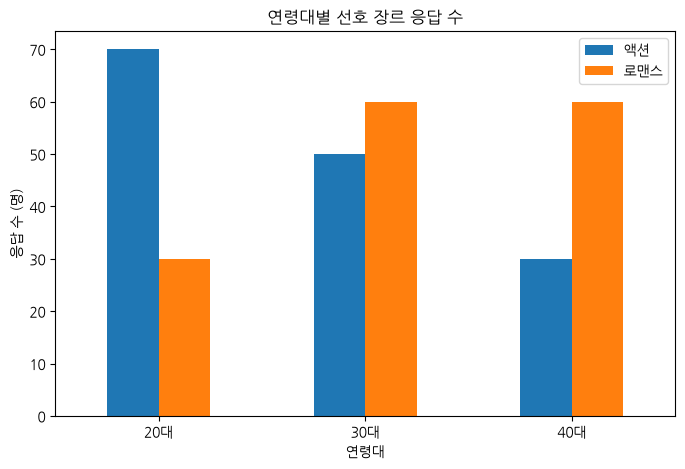

In [26]:
# 데이터 생성 (관측 빈도 분할표)
data = {'액션': [70, 50, 30],
        '로맨스': [30, 60, 60]}
observed = pd.DataFrame(data, index=['20대', '30대', '40대'])

print("관측 빈도 (Observed Frequencies):")
print(observed)

# 분할표 시각화
observed.plot(kind='bar', figsize=(8, 5))
plt.title("연령대별 선호 장르 응답 수")
plt.xlabel("연령대")
plt.ylabel("응답 수 (명)")
plt.xticks(rotation=0)
plt.show()

**📌 아래를 수행해 보세요:**

- 귀무가설(H₀)과 대립가설(H₁)을 세워 봅시다.

- 카이제곱 독립성 검정을 수행하여 카이제곱 통계량, p-값, 자유도, **기대 빈도**를 구해봅시다.

- **"연령대와 선호 장르가 독립이라면"** 어떤 분할표들이 나타날 수 있는지 5,000번 시뮬레이션해 봅시다.

- 시뮬레이션으로 얻은 카이제곱 통계량 분포와 실제 관찰된 카이제곱 통계량을 비교해 봅시다.

In [27]:
# [문제 4] Q1. 귀무가설(H₀)과 대립가설(H₁)을 주석으로 작성해봅시다.
# H₀ (귀무가설):
# H₁ (대립가설):

In [28]:
# [문제 4] Q2. 카이제곱 독립성 검정을 수행하고 카이제곱 통계량, p-값, 자유도, 기대 빈도를 구해봅시다.
# 기대 빈도는 관측 빈도와 비교하기 쉽도록 데이터프레임 형태로 출력해보세요.

# 여기에 코드를 작성해주세요.

In [29]:
# [문제 4] Q3. H₀가 사실(두 변수가 독립)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 각 반복마다 300명의 가상 고객에게 연령대와 장르를 '독립적으로' 할당한 후,
# 가상 분할표를 만들고 카이제곱 통계량을 계산하여 리스트에 저장해보세요.
# 힌트 1: 전체 비율(observed.sum(axis=0) / 전체, observed.sum(axis=1) / 전체)을 확률로 사용
# 힌트 2: np.random.choice 로 300명의 연령대와 장르를 각각 독립적으로 생성
# 힌트 3: pd.crosstab 으로 분할표 생성 후 stats.chi2_contingency 로 통계량 계산

# 여기에 코드를 작성해주세요.

In [30]:
# [문제 4] Q4. 시뮬레이션으로 얻은 카이제곱 통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 카이제곱 통계량을 세로선으로 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

**🧠 데이터를 어떻게 읽을까요?**

- '기대 빈도'는 어떤 의미를 가지며, '관측 빈도'와의 차이가 클수록 카이제곱 통계량은 어떻게 변할까요?

- Q4의 히스토그램은 어떤 분포를 시각화한 것인가요? 실제 관찰된 카이제곱 통계량(세로선)은 흔한 값인가요, 극단적인 값인가요?

- 유의수준 0.05에서, 연령대와 선호 장르 사이에 통계적으로 유의미한 연관성이 있다고 결론 내릴 수 있나요? 그 이유는 무엇인가요?

- 이 결과를 바탕으로 영화관은 연령대별로 어떤 상영 전략이나 프로모션을 세울 수 있을까요?

In [31]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 5. 미니 프로젝트 - 어떤 신규 비료가 가장 효과적일까? (난이도: 상)

**📘 문제**

- 한 농업 연구소에서 새로 개발한 비료 3종류(A, B, C)의 생산량 증대 효과를 비교하고자 합니다.

- 동일한 조건의 밭 30개를 준비하여, 각각 10개씩 비료 A, B, C를 투여한 후 수확량을 측정했습니다.

- 이번 실습에서는 **분산분석(ANOVA)**으로 세 비료 간 평균 수확량에 차이가 있는지 검증하고,
  차이가 있다면 **사후분석(Tukey's HSD)**으로 어떤 비료끼리 차이가 나는지 확인합니다.

- 마지막으로 **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량이 나올 수 있는지 시뮬레이션하고,
  분석 결과를 바탕으로 연구소에 어떤 비료를 추천할지까지 생각해 봅니다.

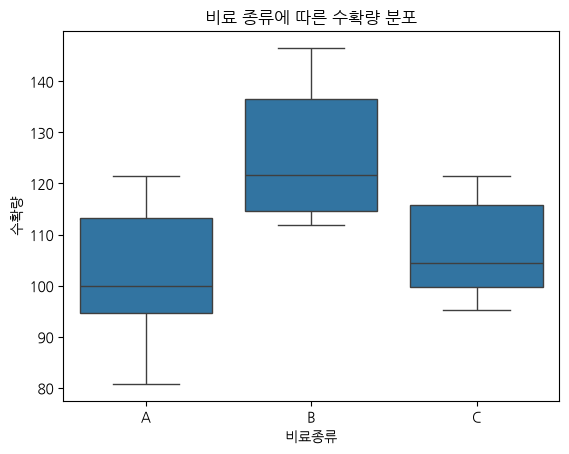

In [32]:
# 데이터 생성 (비료 종류별 수확량)
np.random.seed(123)
fertilizer_a = np.random.normal(loc=105, scale=10, size=10)
fertilizer_b = np.random.normal(loc=120, scale=12, size=10)
fertilizer_c = np.random.normal(loc=108, scale=9, size=10)

# 데이터프레임으로 변환 (사후분석을 위해)
df = pd.DataFrame({'수확량': np.concatenate([fertilizer_a, fertilizer_b, fertilizer_c]),
                   '비료종류': ['A']*10 + ['B']*10 + ['C']*10})

# 데이터 탐색 시각화
sns.boxplot(x='비료종류', y='수확량', data=df)
plt.title("비료 종류에 따른 수확량 분포")
plt.show()

**📌 아래를 수행해 보세요:**

- 세 그룹에 대해 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.

- ANOVA 결과가 유의미할 경우에만 **Tukey's HSD 사후분석**을 수행하고 결과를 해석해 봅시다.

- **"세 비료의 효과가 완전히 똑같다면"** 어떤 F-통계량들이 나오는지 5,000번 시뮬레이션해 봅시다.

- 히스토그램을 그리고, 실제 관찰된 F-통계량이 얼마나 극단적인 값인지 확인해 봅시다.

- 분석 결과를 종합하여 연구소에 추천할 비료를 정해 봅시다.

In [52]:
# [문제 5] Q1. 분산분석(ANOVA)을 수행하여 F-통계량과 p-값을 구해봅시다.
# H₀: 세 비료의 평균 수확량은 모두 같다.
# H₁: 적어도 하나 이상의 비료 평균 수확량은 다르다.

from scipy.stats import f_oneway

f_stat, p_value = f_oneway(fertilizer_a, fertilizer_b, fertilizer_c)

print(f"F-통계량: {f_stat:.4f}")
print(f"p-값: {p_value:.4f}")

F-통계량: 10.3455
p-값: 0.0005


In [53]:
# [문제 5] Q2. ANOVA의 p-값이 유의수준 0.05보다 작을 경우에만
# Tukey's HSD 사후분석을 수행하고 결과를 출력해봅시다.
from statsmodels.stats.multicomp import pairwise_tukeyhsd

alpha = 0.05

if p_value < alpha:
    print("ANOVA 결과 유의미한 차이가 있으므로 사후분석을 수행합니다.\n")
    tukey = pairwise_tukeyhsd(endog=df['수확량'], groups=df['비료종류'], alpha=alpha)
    print(tukey)
else:
    print("ANOVA 결과 유의미한 차이가 없으므로 사후분석을 수행하지 않습니다.")

ANOVA 결과 유의미한 차이가 있으므로 사후분석을 수행합니다.

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B  23.6754 0.0006  10.0402 37.3106   True
     A      C   4.8429 0.6569  -8.7923 18.4781  False
     B      C -18.8325 0.0054 -32.4677 -5.1972   True
-----------------------------------------------------


**📊 Tukey's HSD 사후분석 결과 해석**

| 비교 | 평균 차이 | p-adj | 결론 |
|---|---|---|---|
| A vs B | B가 23.7 높음 | 0.0006 | **차이 있음** ✅ |
| A vs C | C가 4.8 높음 | 0.6569 | 차이 없음 ❌ |
| B vs C | B가 18.8 높음 | 0.0054 | **차이 있음** ✅ |

p-value - 비교를 한 번 했을 때의 p-값   
p-adj - 여러 번 비교한 것을 감안해 보정한 p-값

- **A vs B**: p-adj가 0.0006으로 0.05보다 작으므로, 두 비료의 평균 수확량에는 유의미한 차이가 있다.
    - B 비료가 A 비료보다 평균 약 23.7 더 높다.
- **A vs C**: p-adj가 0.6569로 0.05보다 크므로, 두 비료의 평균 수확량에는 유의미한 차이가 없다.
    - 평균 차이 4.8은 우연으로 충분히 설명될 수 있는 수준이다.
- **B vs C**: p-adj가 0.0054로 0.05보다 작으므로, 두 비료의 평균 수확량에는 유의미한 차이가 있다.
    - B 비료가 C 비료보다 평균 약 18.8 더 높다.

**✅ 결론**

- **B 비료**는 A, C 비료보다 평균 수확량이 통계적으로 유의미하게 높다.
- **A와 C 비료**는 평균 수확량에 유의미한 차이가 없다.
- 이는 박스플롯에서 B의 상자만 위쪽에 있고, A와 C의 상자가 겹쳐 있던 모습과 일치한다.

In [56]:
# [문제 5] Q3. H₀가 사실(세 그룹의 평균이 모두 같다)이라고 가정하고 시뮬레이션을 5,000번 수행해봅시다.
# 모든 데이터를 합친 평균과 표준편차를 가진 H₀ 모집단에서 10개씩 3개의 가상 그룹을 생성하고,
# 이 가상 그룹들로 ANOVA를 수행하여 F-통계량을 리스트에 저장해보세요.

# 1. 30개 밭 전체 데이터의 평균과 표준편차 (H₀ 모집단)
pooled_mean = df['수확량'].mean()
pooled_std = df['수확량'].std()
print(f"전체 평균: {pooled_mean:.2f}, 전체 표준편차: {pooled_std:.2f}")

# 2. 시뮬레이션
np.random.seed(42)
n_sim = 5000
f_stats_sim = []   # F-통계량을 저장할 리스트

for _ in range(n_sim):
    # 같은 모집단에서 10개씩 3그룹 생성 → 세 비료 효과가 똑같은 상황
    group1 = np.random.normal(loc=pooled_mean, scale=pooled_std, size=10)
    group2 = np.random.normal(loc=pooled_mean, scale=pooled_std, size=10)
    group3 = np.random.normal(loc=pooled_mean, scale=pooled_std, size=10)

    f_sim, _ = f_oneway(group1, group2, group3)
    f_stats_sim.append(f_sim)

print("앞 5개 F-통계량:", np.round(f_stats_sim[:5], 3))
print(f"시뮬레이션 F-통계량 평균: {np.mean(f_stats_sim):.3f}")

전체 평균: 111.81, 전체 표준편차: 15.77
앞 5개 F-통계량: [6.569 0.892 0.058 0.244 0.314]
시뮬레이션 F-통계량 평균: 1.115


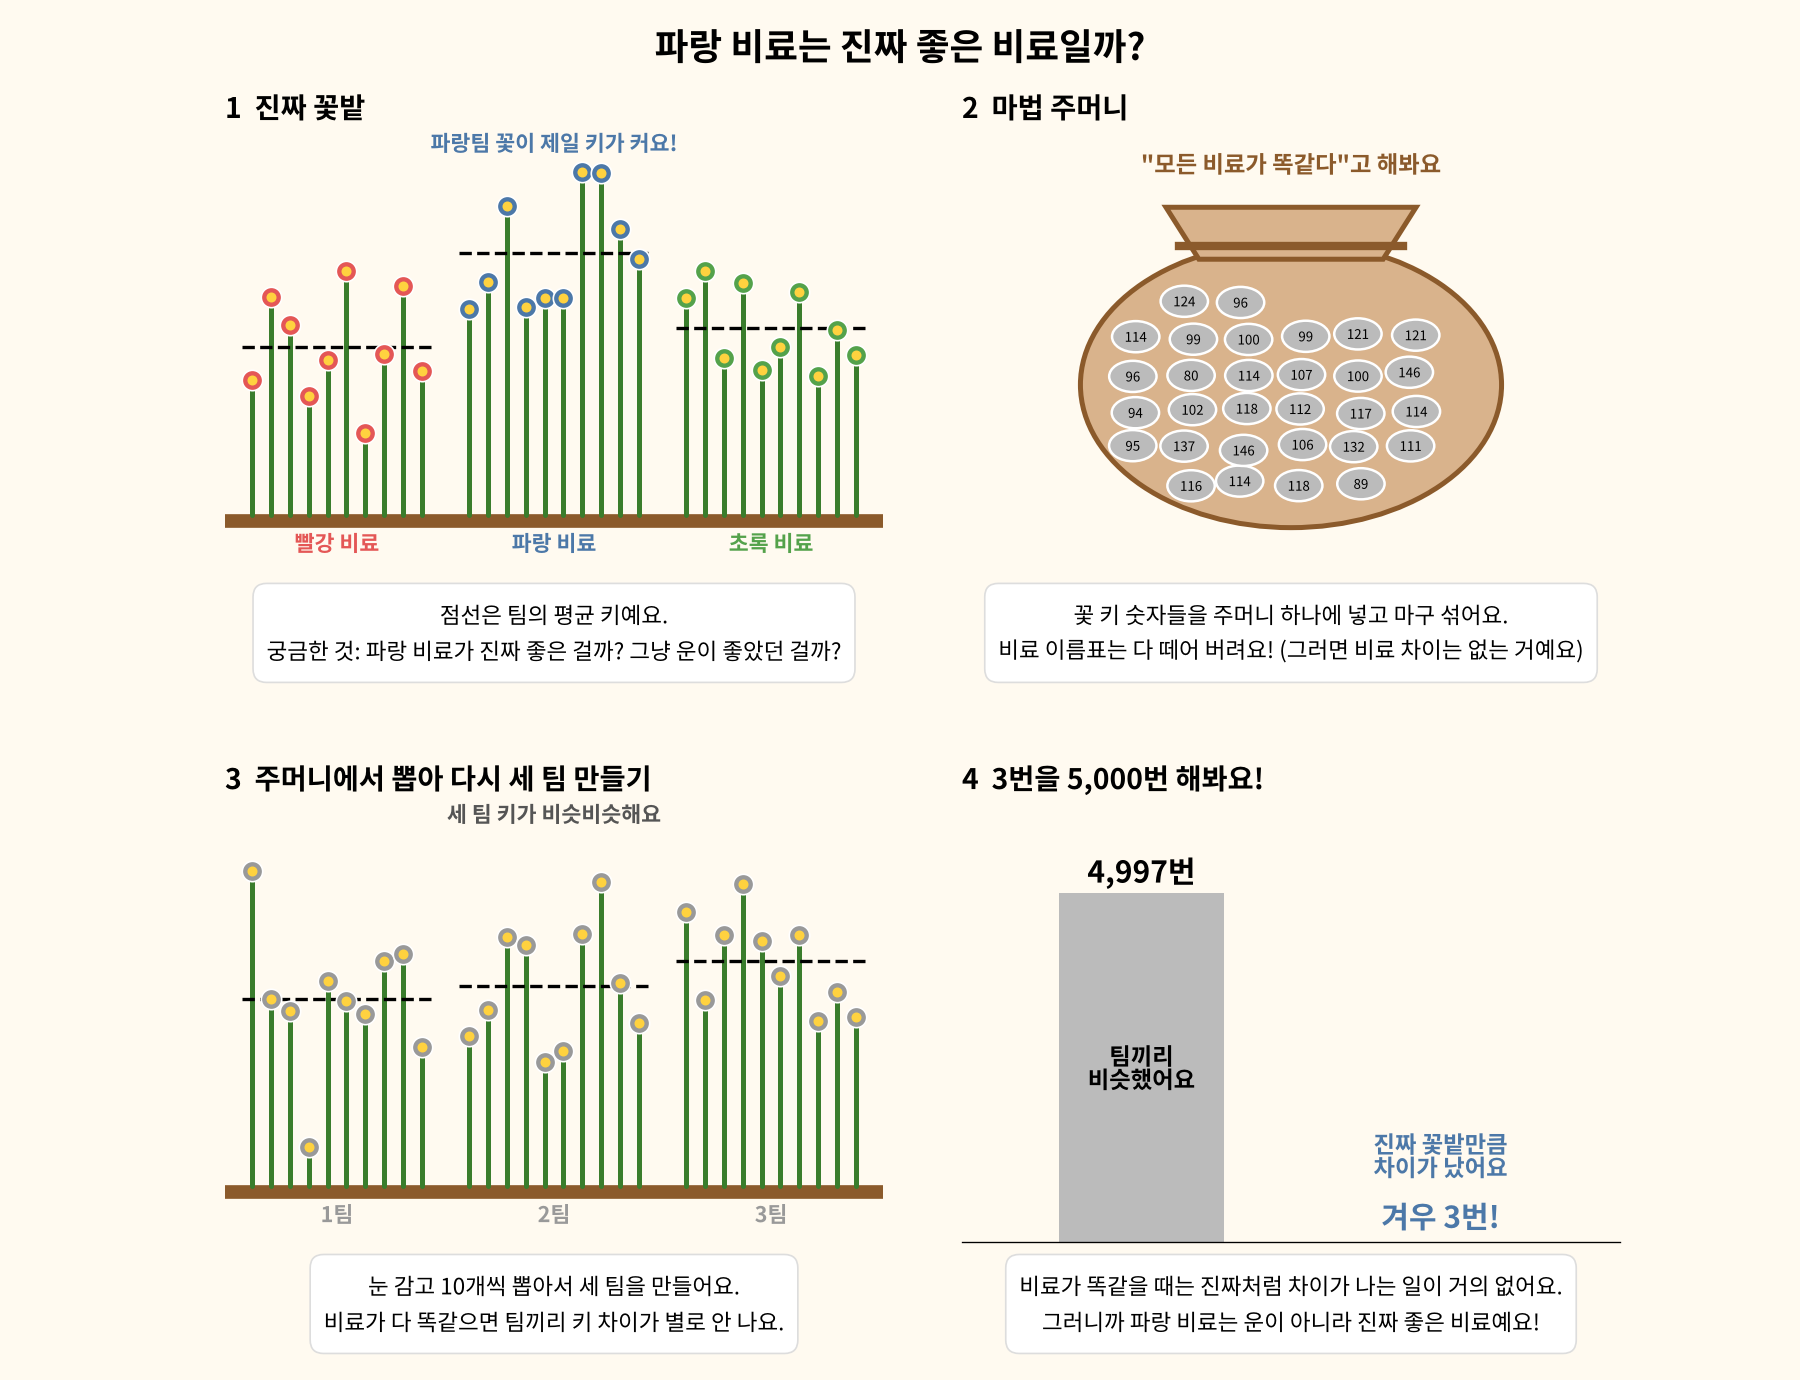

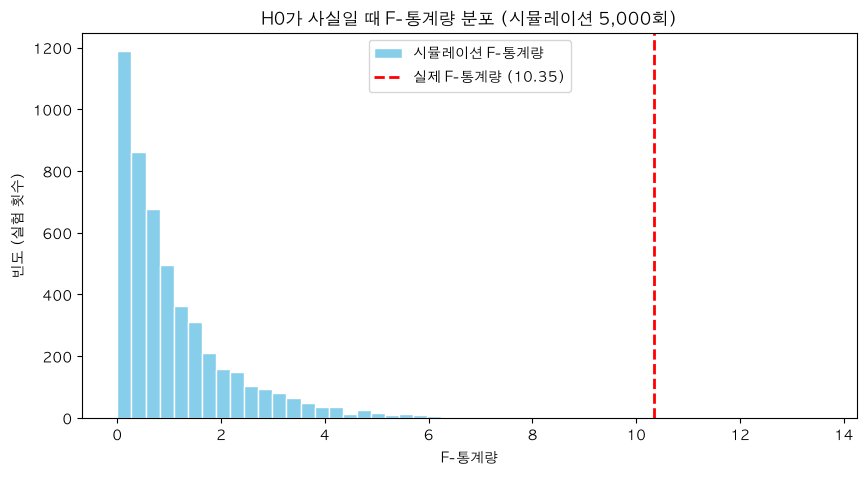

실제 F 이상이 나온 횟수: 3번 / 5000번
시뮬레이션 p-값: 0.0006


In [57]:
# [문제 5] Q4. 시뮬레이션으로 얻은 F-통계량의 분포를 히스토그램으로 그려봅시다.
# 실제 관찰된 F-통계량을 세로선으로 함께 표시해 봅시다.
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

f_stats_sim = np.array(f_stats_sim)   # 리스트를 배열로 변환

plt.figure(figsize=(10, 5))
plt.hist(f_stats_sim, bins=50, color='skyblue', edgecolor='white', label='시뮬레이션 F-통계량')

# 실제 관찰된 F-통계량 세로선 (Q1에서 구한 f_stat)
plt.axvline(f_stat, color='red', linestyle='--', linewidth=2,
            label=f'실제 F-통계량 ({f_stat:.2f})')

plt.title('H0가 사실일 때 F-통계량 분포 (시뮬레이션 5,000회)')
plt.xlabel('F-통계량')
plt.ylabel('빈도 (실험 횟수)')
plt.legend()
plt.show()

# 시뮬레이션에서 실제 F 이상이 나온 비율 (시뮬레이션 p-값)
sim_p = (f_stats_sim >= f_stat).mean()
print(f"실제 F 이상이 나온 횟수: {(f_stats_sim >= f_stat).sum()}번 / {len(f_stats_sim)}번")
print(f"시뮬레이션 p-값: {sim_p:.4f}")

**🌱 연구소에 추천하는 비료: 비료 B**

**1. 분산분석(ANOVA) 결과**

- F-통계량 10.35, p-값 0.0005로 유의수준 0.05보다 작아 귀무가설을 기각했다.
    - 즉, 세 비료 중 적어도 하나는 평균 수확량이 다르다.

**2. 사후분석(Tukey's HSD) 결과**

| 비교 | 평균 차이 | p-adj | 결론 |
|---|---|---|---|
| A vs B | B가 23.7 높음 | 0.0006 | **차이 있음** ✅ |
| A vs C | C가 4.8 높음 | 0.6569 | 차이 없음 ❌ |
| B vs C | B가 18.8 높음 | 0.0054 | **차이 있음** ✅ |

- B는 A, C보다 평균 수확량이 통계적으로 유의미하게 높다.
- A와 C는 유의미한 차이가 없다.

**3. 시뮬레이션 결과**

- 세 비료 효과가 같다고 가정하고 5,000번 시뮬레이션했을 때, 실제 F-통계량(10.35) 이상이 나온 경우는 3번(0.06%)뿐이었다.
    - 따라서 B의 높은 수확량은 우연이 아니라 실제 비료 효과로 볼 수 있다.

**✅ 결론**

- 평균 수확량이 가장 높고, 다른 두 비료와의 차이가 통계적으로 유의미한 **비료 B를 추천한다.**

**📝 참고 사항**

- A와 C는 수확량 차이가 없으므로, B를 사용할 수 없는 경우 두 비료 중 가격이 더 저렴한 쪽을 선택하는 것이 합리적이다.
- 비료당 밭이 10개로 표본이 작으므로, 실제 도입 전에 더 많은 밭에서 추가 실험을 해보는 것이 좋다.
- 수확량 외에도 비료 가격, 토양에 미치는 영향 등을 함께 고려해야 한다.

**🧠 데이터를 어떻게 읽을까요?**

- ANOVA 검정의 p-값을 통해 어떤 결론을 내릴 수 있나요? 이 결과는 "세 비료가 모두 동일한 효과를 가진다"는 뜻인가요, "적어도 하나는 다르다"는 뜻인가요?

- Tukey's HSD 결과표의 `reject` 열에서 `True`로 표시된 조합은 무엇이며, 이는 무엇을 의미하나요?

- `meandiff` 열의 값은 어떤 정보를 주나요? 신뢰구간(`lower`, `upper`)이 0을 포함하는지 여부는 무엇을 뜻할까요?

- 그룹별 표본 크기가 10개로 작다는 점은 이 결론의 신뢰도에 어떤 영향을 줄까요? 어떻게 개선할 수 있을까요?

**🧠 데이터를 어떻게 읽을까요?**

- **ANOVA 검정의 p-값을 통해 어떤 결론을 내릴 수 있나요? "세 비료가 모두 동일한 효과를 가진다"는 뜻인가요, "적어도 하나는 다르다"는 뜻인가요?**
    - p-값이 0.0005로 유의수준 0.05보다 작으므로 귀무가설을 기각한다.
    - 따라서 **"적어도 하나의 비료는 평균 수확량이 다르다"**는 뜻이다.
    - 단, ANOVA는 "어딘가 다르다"까지만 알려줄 뿐, **어떤 비료끼리 다른지는 알려주지 않는다.** 이를 확인하기 위해 사후분석(Tukey's HSD)이 필요하다.

- **Tukey's HSD 결과표의 `reject` 열에서 `True`로 표시된 조합은 무엇이며, 이는 무엇을 의미하나요?**
    - `True`인 조합은 **A vs B**, **B vs C** 두 가지이다.
    - 이 두 조합은 평균 수확량에 **통계적으로 유의미한 차이가 있다**는 뜻이다.
    - 반면 A vs C는 `False`로, 두 비료의 수확량 차이는 우연으로 설명될 수 있는 수준이다.
    - 결국 **B만 다른 두 비료와 확실히 구별된다**는 것을 알 수 있다.

- **`meandiff` 열의 값은 어떤 정보를 주나요? 신뢰구간(`lower`, `upper`)이 0을 포함하는지 여부는 무엇을 뜻할까요?**
    - `meandiff`는 **두 그룹의 평균 차이(group2 − group1)**로, 차이의 방향과 크기를 알려준다.
        - A vs B: +23.7 → B가 A보다 23.7 높다.
        - B vs C: −18.8 → C가 B보다 18.8 낮다 (B가 더 높다).
    - 신뢰구간은 "진짜 평균 차이가 있을 것으로 보이는 범위"이다.

    | 비교 | 신뢰구간 | 0 포함? | 의미 |
    |---|---|---|---|
    | A vs B | 10.04 ~ 37.31 | ❌ | 차이가 확실히 있다 |
    | A vs C | −8.79 ~ 18.48 | ✅ | 차이가 0일 수도 있다 |
    | B vs C | −32.47 ~ −5.20 | ❌ | 차이가 확실히 있다 |   



    - 신뢰구간이 **0을 포함하면** "차이가 없을 수도 있다" → `reject = False`
    - 신뢰구간이 **0을 포함하지 않으면** "차이가 확실히 있다" → `reject = True`

- **그룹별 표본 크기가 10개로 작다는 점은 이 결론의 신뢰도에 어떤 영향을 줄까요? 어떻게 개선할 수 있을까요?**
    - 표본이 작으면 **우연의 영향을 크게 받는다.** 운 좋은 밭 몇 개만으로도 평균이 크게 흔들릴 수 있다.
    - 그래서 신뢰구간이 넓어지고(예: A vs B는 10~37로 범위가 넓음), 실제 차이가 있어도 발견하지 못할 수 있다.
        - A vs C의 차이(4.8)도 표본이 더 많았다면 유의미하게 나왔을 가능성이 있다.
    - **개선 방법**
        - 비료당 밭의 수를 늘려 실험한다. (예: 10개 → 30개 이상)
        - 다른 지역이나 다른 시기에 반복 실험하여 결과가 일관되게 나오는지 확인한다.
        - 흙 상태, 햇빛 등 수확량에 영향을 주는 다른 조건을 최대한 똑같이 맞춘다.